In [ ]:
# Name = Vibhor

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

df_raw = pd.read_csv("vibhor_sports_staff_schedule.csv")

print("Raw Shape:", df_raw.shape)
print(df_raw.head())
print(df_raw.info())
print("Missing Values:\n", df_raw.isnull().sum())
print("Duplicate Rows:", df_raw.duplicated().sum())

Raw Shape: (114, 8)
  schedule_id staff_id             role day_of_week              time_slot  \
0      SCH001    STF06  Physiotherapist      Monday  Morning (07:00-09:00)   
1      SCH002    STF01           coach       Monday  Morning (07:00-09:00)   
2      SCH003    STF10    Support Staff      Monday  Morning (07:00-09:00)   
3      SCH004    STF07  Physiotherapist      Monday  Morning (07:00-09:00)   
4      SCH005    STF03            Coach      Monday  Morning (07:00-09:00)   

         session_type  duration_hours available_flag  
0  Fitness Assessment             2.0            Yes  
1          Match Prep             2.0            Yes  
2        Injury Rehab             2.0            Yes  
3     Equipment Setup             2.0            Yes  
4  Fitness Assessment             NaN            Yes  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114 entries, 0 to 113
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          -----------

In [12]:
df = df_raw.drop_duplicates().copy()
df["role"] = df["role"].str.strip().str.title()
df["duration_hours"] = df["duration_hours"].fillna(df["duration_hours"].median())
df["session_type"] = df["session_type"].fillna("General Session")

print("Cleaned Shape:", df.shape)
print("Missing After Cleaning:\n", df.isnull().sum())

Cleaned Shape: (112, 8)
Missing After Cleaning:
 schedule_id       0
staff_id          0
role              0
day_of_week       0
time_slot         0
session_type      0
duration_hours    0
available_flag    0
dtype: int64


In [13]:
overlaps = df[df.duplicated(subset=["staff_id", "day_of_week", "time_slot"], keep=False)]
print("Double-Booked Overlaps:", df.duplicated(subset=["staff_id", "day_of_week", "time_slot"]).sum())
print(overlaps.sort_values(["day_of_week", "time_slot", "staff_id"]))

avail_conflicts = df[df["available_flag"] == "No"]
print("\nAvailability Conflicts:", len(avail_conflicts))
print(avail_conflicts)

Double-Booked Overlaps: 2
    schedule_id staff_id             role day_of_week              time_slot  \
79       SCH080    STF06  Physiotherapist      Friday  Evening (17:00-19:00)   
110      SCH111    STF06  Physiotherapist      Friday  Evening (17:00-19:00)   
28       SCH029    STF02            Coach     Tuesday  Evening (17:00-19:00)   
111      SCH112    STF02            Coach     Tuesday  Evening (17:00-19:00)   

                session_type  duration_hours available_flag  
79   Strength & Conditioning             2.0            Yes  
110             Injury Rehab             2.0            Yes  
28   Strength & Conditioning             2.0            Yes  
111           Tactical Drill             2.0            Yes  

Availability Conflicts: 2
    schedule_id staff_id             role day_of_week              time_slot  \
98       SCH099    STF07  Physiotherapist      Sunday  Morning (07:00-09:00)   
101      SCH102    STF06  Physiotherapist      Sunday  Morning (07:00-09:00)

In [14]:
role_summary = df.groupby("role").agg(
    unique_staff=("staff_id", "nunique"),
    total_sessions=("schedule_id", "count"),
    total_hours=("duration_hours", "sum")
).reset_index()
role_summary["avg_hours_per_staff"] = (role_summary["total_hours"] / role_summary["unique_staff"]).round(2)
print("\nWorkload by Role:\n", role_summary)

staff_summary = df.groupby(["staff_id", "role"]).agg(
    sessions=("schedule_id", "count"),
    total_hours=("duration_hours", "sum")
).reset_index().sort_values("total_hours", ascending=False)
print("\nWorkload by Staff Member:\n", staff_summary)

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
slots = ["Morning (07:00-09:00)", "Midday (10:00-12:00)", "Afternoon (14:00-16:00)", "Evening (17:00-19:00)"]
coverage_matrix = df.pivot_table(
    index="day_of_week",
    columns="time_slot",
    values="staff_id",
    aggfunc="count",
    fill_value=0
).reindex(index=days, columns=slots)
print("\nStaffing Coverage Matrix:\n", coverage_matrix)


Workload by Role:
               role  unique_staff  total_sessions  total_hours  \
0            Coach             3              40         80.0   
1  Physiotherapist             2              24         48.0   
2    Support Staff             3              32         64.0   
3          Trainer             2              16         32.0   

   avg_hours_per_staff  
0                26.67  
1                24.00  
2                21.33  
3                16.00  

Workload by Staff Member:
   staff_id             role  sessions  total_hours
1    STF02            Coach        17         34.0
9    STF10    Support Staff        15         30.0
6    STF07  Physiotherapist        13         26.0
2    STF03            Coach        13         26.0
4    STF05          Trainer        13         26.0
8    STF09    Support Staff        11         22.0
5    STF06  Physiotherapist        11         22.0
0    STF01            Coach        10         20.0
7    STF08    Support Staff         6     

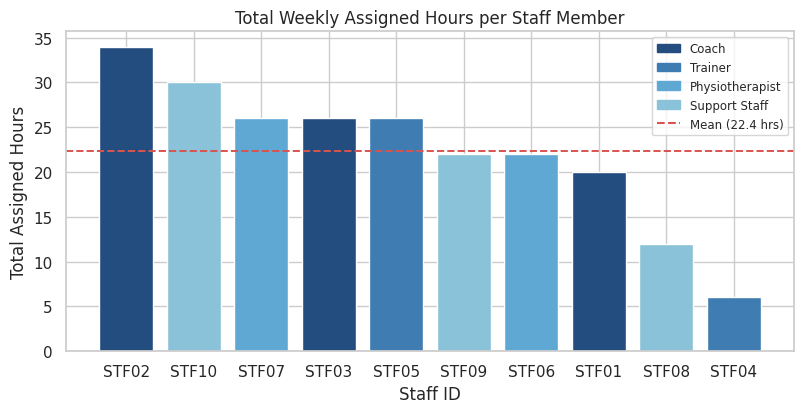

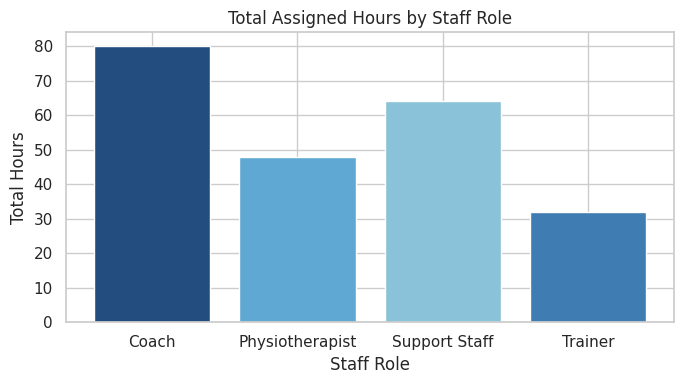

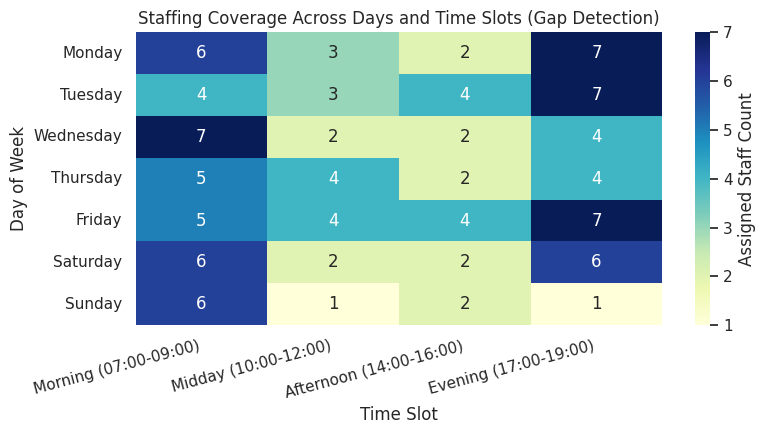

In [15]:
sns.set_theme(style="whitegrid")
role_palette = {
    "Coach": "#234d7e",
    "Trainer": "#3e7cb1",
    "Physiotherapist": "#5fa8d3",
    "Support Staff": "#89c2d9"
}

plt.figure(figsize=(8.2, 4.3))
plt.bar(staff_summary["staff_id"], staff_summary["total_hours"], color=[role_palette[r] for r in staff_summary["role"]])
plt.axhline(staff_summary["total_hours"].mean(), color="#d9534f", linestyle="--", linewidth=1.4)
legend_handles = [Patch(color=c, label=r) for r, c in role_palette.items()] + [
    plt.Line2D([0], [0], color="#d9534f", linestyle="--", label=f"Mean ({staff_summary['total_hours'].mean():.1f} hrs)")
]
plt.legend(handles=legend_handles, loc="upper right", fontsize=8.5)
plt.title("Total Weekly Assigned Hours per Staff Member")
plt.xlabel("Staff ID")
plt.ylabel("Total Assigned Hours")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.bar(role_summary["role"], role_summary["total_hours"], color=[role_palette[r] for r in role_summary["role"]])
plt.title("Total Assigned Hours by Staff Role")
plt.xlabel("Staff Role")
plt.ylabel("Total Hours")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8.2, 4.5))
sns.heatmap(coverage_matrix, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={"label": "Assigned Staff Count"})
plt.title("Staffing Coverage Across Days and Time Slots (Gap Detection)")
plt.xlabel("Time Slot")
plt.ylabel("Day of Week")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()